In [1]:
%pip install scikit-learn matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ============================================================
# STEP 01.5 — t-SNE VISUALIZATION
# Knowledge-Level Cross-Modal Representation Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.manifold import TSNE

print("=" * 100)
print("STEP 01.5 — t-SNE VISUALIZATION")
print("=" * 100)

# ------------------------------------------------------------
# Resolve Project Root
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "05_multimodal_fusion").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Project root could not be located.")
    PROJECT_ROOT = PROJECT_ROOT.parent

print("\nProject Root:")
print(PROJECT_ROOT)

# ------------------------------------------------------------
# Output Directories
# ------------------------------------------------------------

FIGURE_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "figures"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "reports"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("\nFigure Directory:")
print(FIGURE_DIR)

print("\nReport Directory:")
print(REPORT_DIR)

STEP 01.5 — t-SNE VISUALIZATION

Project Root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

Figure Directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures

Report Directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports


In [3]:
# ============================================================
# LOAD FROZEN 32D EMBEDDINGS
# ============================================================

FUSION_DIR = PROJECT_ROOT / "05_multimodal_fusion"

# ------------------------------------------------------------
# Genetic
# ------------------------------------------------------------

genetic_embeddings = np.load(
    FUSION_DIR / "genetic_32d_normalized.npy"
)

genetic_labels = np.load(
    FUSION_DIR / "genetic_targets.npy"
)

# ------------------------------------------------------------
# Behavioral
# ------------------------------------------------------------

behavioral_embeddings = np.load(
    FUSION_DIR / "behavioral_32d_normalized.npy"
)

behavioral_labels = np.load(
    FUSION_DIR / "behavioral_targets.npy"
)

# ------------------------------------------------------------
# Environmental
# ------------------------------------------------------------

environmental_embeddings = np.load(
    FUSION_DIR / "environmental_32d_normalized.npy"
)

environmental_labels = np.load(
    FUSION_DIR / "environmental_targets.npy"
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 100)
print("FROZEN BASELINE EMBEDDINGS LOADED")
print("=" * 100)

modalities = {
    "Genetic": (genetic_embeddings, genetic_labels),
    "Behavioral": (behavioral_embeddings, behavioral_labels),
    "Environmental": (environmental_embeddings, environmental_labels)
}

for modality, (embeddings, labels) in modalities.items():
    
    print(f"\n{modality.upper()}")
    print("-" * 60)
    print(f"Embedding shape : {embeddings.shape}")
    print(f"Label shape     : {labels.shape}")
    print(f"Unique labels   : {np.unique(labels)}")
    
    unique, counts = np.unique(labels, return_counts=True)
    
    print(
        f"Class distribution: "
        f"{dict(zip(unique, counts))}"
    )

FROZEN BASELINE EMBEDDINGS LOADED

GENETIC
------------------------------------------------------------
Embedding shape : (116, 32)
Label shape     : (116,)
Unique labels   : [0 1]
Class distribution: {np.int64(0): np.int64(29), np.int64(1): np.int64(87)}

BEHAVIORAL
------------------------------------------------------------
Embedding shape : (880, 32)
Label shape     : (880,)
Unique labels   : [0 1]
Class distribution: {np.int64(0): np.int64(439), np.int64(1): np.int64(441)}

ENVIRONMENTAL
------------------------------------------------------------
Embedding shape : (47768, 32)
Label shape     : (47768,)
Unique labels   : [0 1]
Class distribution: {np.int64(0): np.int64(45650), np.int64(1): np.int64(2118)}


In [4]:
# ============================================================
# BALANCED CLASS-AWARE SAMPLING
# ============================================================

RANDOM_STATE = 42

# Genetic determines the reference class counts
genetic_class_0_count = np.sum(genetic_labels == 0)
genetic_class_1_count = np.sum(genetic_labels == 1)

TARGET_CLASS_COUNTS = {
    0: genetic_class_0_count,
    1: genetic_class_1_count
}

print("=" * 100)
print("BALANCED SAMPLING CONFIGURATION")
print("=" * 100)

print("\nReference class counts:")
print(f"Class 0 (NON-ASD): {TARGET_CLASS_COUNTS[0]}")
print(f"Class 1 (ASD)    : {TARGET_CLASS_COUNTS[1]}")

rng = np.random.default_rng(RANDOM_STATE)


def balanced_class_sampling(embeddings, labels, modality_name):
    
    selected_indices = []
    
    for class_label, target_count in TARGET_CLASS_COUNTS.items():
        
        class_indices = np.where(labels == class_label)[0]
        
        if len(class_indices) < target_count:
            raise ValueError(
                f"{modality_name} does not have enough samples "
                f"for class {class_label}"
            )
        
        sampled_indices = rng.choice(
            class_indices,
            size=target_count,
            replace=False
        )
        
        selected_indices.extend(sampled_indices)
    
    selected_indices = np.array(selected_indices)
    
    return (
        embeddings[selected_indices],
        labels[selected_indices]
    )


# ------------------------------------------------------------
# Apply Sampling
# ------------------------------------------------------------

genetic_balanced, genetic_labels_balanced = balanced_class_sampling(
    genetic_embeddings,
    genetic_labels,
    "Genetic"
)

behavioral_balanced, behavioral_labels_balanced = balanced_class_sampling(
    behavioral_embeddings,
    behavioral_labels,
    "Behavioral"
)

environmental_balanced, environmental_labels_balanced = balanced_class_sampling(
    environmental_embeddings,
    environmental_labels,
    "Environmental"
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

sampling_summary = []

for modality_name, embeddings, labels in [
    ("Genetic", genetic_balanced, genetic_labels_balanced),
    ("Behavioral", behavioral_balanced, behavioral_labels_balanced),
    ("Environmental", environmental_balanced, environmental_labels_balanced)
]:
    
    sampling_summary.append({
        "Modality": modality_name,
        "Class_0_Count": int(np.sum(labels == 0)),
        "Class_1_Count": int(np.sum(labels == 1)),
        "Total_Samples": len(labels)
    })

sampling_summary_df = pd.DataFrame(sampling_summary)

print("\n")
print("=" * 100)
print("BALANCED SAMPLING SUMMARY")
print("=" * 100)

display(sampling_summary_df)

BALANCED SAMPLING CONFIGURATION

Reference class counts:
Class 0 (NON-ASD): 29
Class 1 (ASD)    : 87


BALANCED SAMPLING SUMMARY


,Modality,Class_0_Count,Class_1_Count,Total_Samples
0,Genetic,29,87,116
1,Behavioral,29,87,116
2,Environmental,29,87,116


In [5]:
# ============================================================
# COMBINE BALANCED REPRESENTATIONS
# ============================================================

combined_embeddings = np.vstack([
    genetic_balanced,
    behavioral_balanced,
    environmental_balanced
])

combined_labels = np.concatenate([
    genetic_labels_balanced,
    behavioral_labels_balanced,
    environmental_labels_balanced
])

combined_modalities = np.array(
    ["Genetic"] * len(genetic_balanced)
    + ["Behavioral"] * len(behavioral_balanced)
    + ["Environmental"] * len(environmental_balanced)
)

print("=" * 100)
print("COMBINED KNOWLEDGE-LEVEL REPRESENTATION SPACE")
print("=" * 100)

print(f"\nCombined embedding shape: {combined_embeddings.shape}")
print(f"Combined label shape    : {combined_labels.shape}")

print("\nSamples per modality:")

for modality in np.unique(combined_modalities):
    count = np.sum(combined_modalities == modality)
    print(f"{modality}: {count}")

print("\nImportant:")
print(
    "These samples are NOT patient-matched across modalities."
)
print(
    "t-SNE is being used to visualize knowledge-level relationships "
    "between learned modality representations."
)

COMBINED KNOWLEDGE-LEVEL REPRESENTATION SPACE

Combined embedding shape: (348, 32)
Combined label shape    : (348,)

Samples per modality:
Behavioral: 116
Environmental: 116
Genetic: 116

Important:
These samples are NOT patient-matched across modalities.
t-SNE is being used to visualize knowledge-level relationships between learned modality representations.


In [6]:
# ============================================================
# t-SNE DIMENSIONALITY REDUCTION
# ============================================================

print("=" * 100)
print("RUNNING t-SNE")
print("=" * 100)

print("\nConfiguration:")
print("Components   : 2")
print("Perplexity   : 30")
print("Iterations   : 1500")
print("Random State : 42")
print("Samples      :", len(combined_embeddings))

tsne = TSNE(
    n_components=2,
    perplexity=30,
    max_iter=1500,
    init="pca",
    learning_rate="auto",
    random_state=42
)

tsne_result = tsne.fit_transform(combined_embeddings)

print("\nt-SNE completed successfully.")
print("Output shape:", tsne_result.shape)

RUNNING t-SNE

Configuration:
Components   : 2
Perplexity   : 30
Iterations   : 1500
Random State : 42
Samples      : 348

t-SNE completed successfully.
Output shape: (348, 2)


In [7]:
# ============================================================
# SAVE t-SNE COORDINATES
# ============================================================

tsne_coordinates_df = pd.DataFrame({
    "TSNE_1": tsne_result[:, 0],
    "TSNE_2": tsne_result[:, 1],
    "Modality": combined_modalities,
    "Class": combined_labels
})

tsne_coordinates_path = (
    REPORT_DIR
    / "01_05_tsne_coordinates.csv"
)

tsne_coordinates_df.to_csv(
    tsne_coordinates_path,
    index=False
)

print("=" * 100)
print("t-SNE COORDINATES SAVED")
print("=" * 100)

print(tsne_coordinates_path)

display(tsne_coordinates_df.head())

t-SNE COORDINATES SAVED
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_05_tsne_coordinates.csv


,TSNE_1,TSNE_2,Modality,Class
0,-1.582874,6.057808,Genetic,0
1,15.120742,-1.157868,Genetic,0
2,-1.634119,6.334320,Genetic,0
3,8.858691,2.033396,Genetic,0
4,8.439540,6.106483,Genetic,0


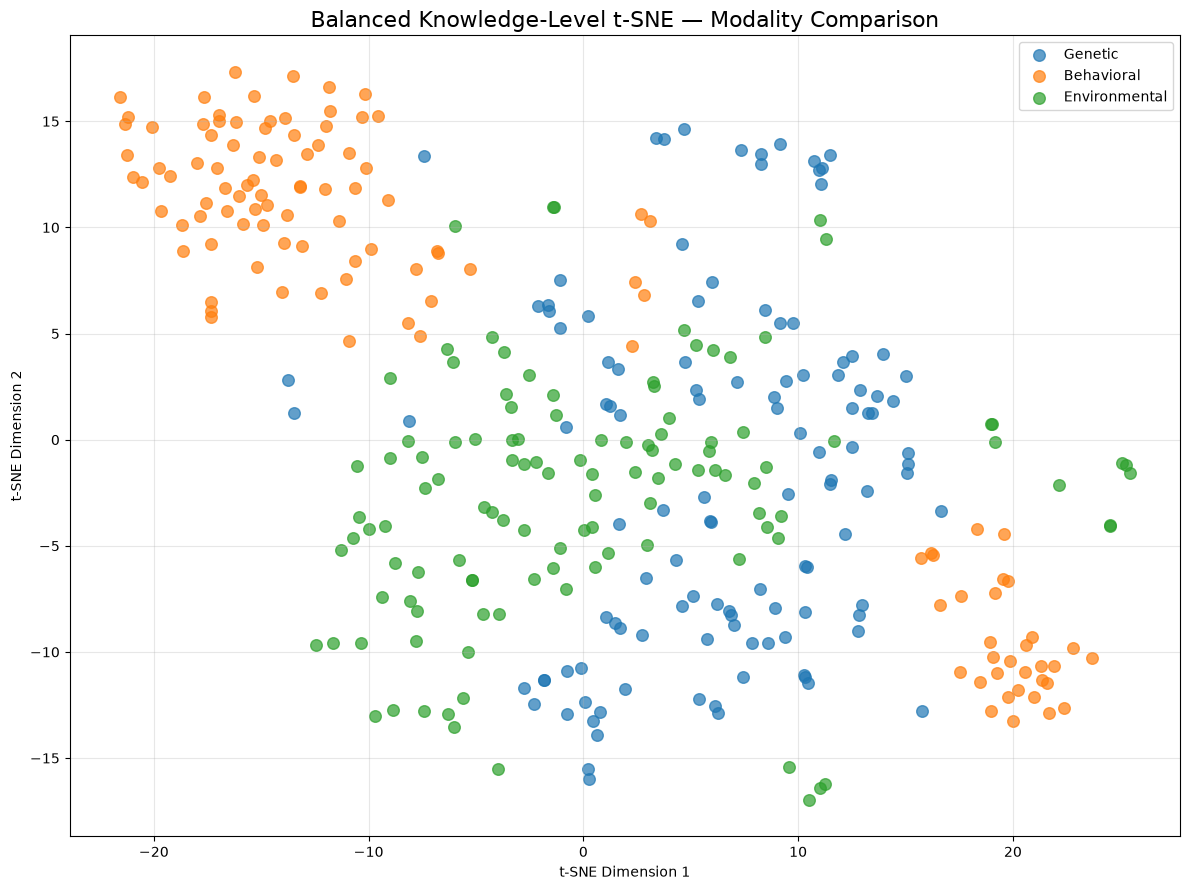

Figure saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_05_tsne_by_modality.png


In [8]:
# ============================================================
# t-SNE — MODALITY COMPARISON
# ============================================================

plt.figure(figsize=(12, 9))

for modality in ["Genetic", "Behavioral", "Environmental"]:
    
    mask = combined_modalities == modality
    
    plt.scatter(
        tsne_result[mask, 0],
        tsne_result[mask, 1],
        label=modality,
        alpha=0.7,
        s=70
    )

plt.title(
    "Balanced Knowledge-Level t-SNE — Modality Comparison",
    fontsize=16
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "01_05_tsne_by_modality.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:")
print(figure_path)

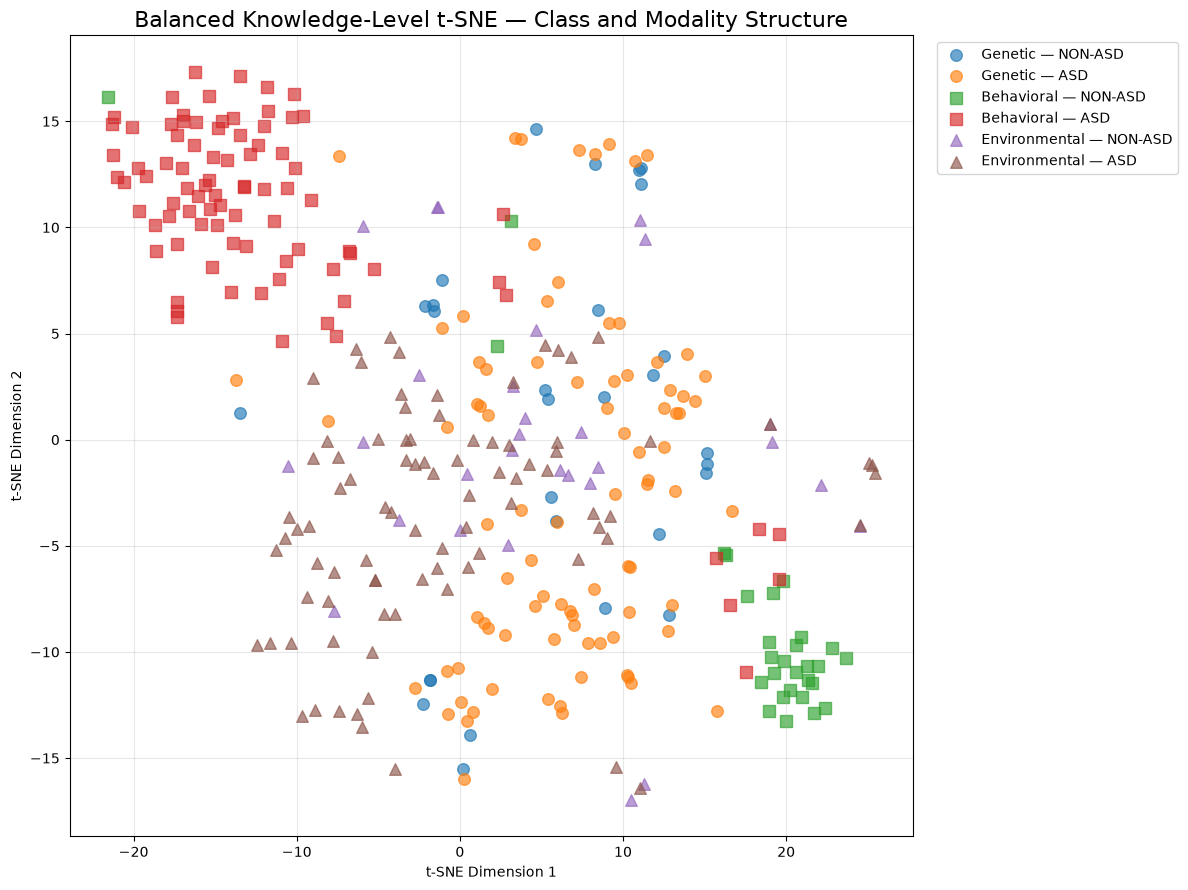

Figure saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_05_tsne_class_and_modality.png


In [9]:
# ============================================================
# t-SNE — CLASS AND MODALITY STRUCTURE
# ============================================================

plt.figure(figsize=(12, 9))

plot_config = {
    ("Genetic", 0): {
        "label": "Genetic — NON-ASD",
        "marker": "o"
    },
    ("Genetic", 1): {
        "label": "Genetic — ASD",
        "marker": "o"
    },
    ("Behavioral", 0): {
        "label": "Behavioral — NON-ASD",
        "marker": "s"
    },
    ("Behavioral", 1): {
        "label": "Behavioral — ASD",
        "marker": "s"
    },
    ("Environmental", 0): {
        "label": "Environmental — NON-ASD",
        "marker": "^"
    },
    ("Environmental", 1): {
        "label": "Environmental — ASD",
        "marker": "^"
    }
}


for (modality, class_label), config in plot_config.items():
    
    mask = (
        (combined_modalities == modality)
        & (combined_labels == class_label)
    )
    
    plt.scatter(
        tsne_result[mask, 0],
        tsne_result[mask, 1],
        marker=config["marker"],
        label=config["label"],
        alpha=0.65,
        s=70
    )


plt.title(
    "Balanced Knowledge-Level t-SNE — Class and Modality Structure",
    fontsize=16
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "01_05_tsne_class_and_modality.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:")
print(figure_path)

In [10]:
# ============================================================
# STEP 01.5 — FINAL SUMMARY
# ============================================================

summary_data = {
    "Parameter": [
        "Analysis Level",
        "Patient-Level Matching Used",
        "Total Balanced Samples",
        "Samples Per Modality",
        "Embedding Dimension Input",
        "t-SNE Output Dimension",
        "Perplexity",
        "Iterations",
        "Random State"
    ],
    
    "Value": [
        "Knowledge-Level Cross-Modal Analysis",
        "No",
        len(combined_embeddings),
        len(genetic_balanced),
        combined_embeddings.shape[1],
        2,
        30,
        1500,
        42
    ]
}

tsne_summary_df = pd.DataFrame(summary_data)

summary_path = (
    REPORT_DIR
    / "01_05_tsne_configuration_summary.csv"
)

tsne_summary_df.to_csv(
    summary_path,
    index=False
)

print("=" * 100)
print("STEP 01.5 — t-SNE VISUALIZATION COMPLETED")
print("=" * 100)

print("\nAnalysis Type:")
print("Knowledge-Level Cross-Modal Representation Analysis")

print("\nPatient-level matching:")
print("NOT USED")

print("\nBalanced Sampling:")
print("Genetic       :", len(genetic_balanced))
print("Behavioral    :", len(behavioral_balanced))
print("Environmental :", len(environmental_balanced))

print("\nTotal combined samples:", len(combined_embeddings))

print("\nGenerated Figures:")
print("1. 01_05_tsne_by_modality.png")
print("2. 01_05_tsne_class_and_modality.png")

print("\nGenerated Reports:")
print("1. 01_05_tsne_coordinates.csv")
print("2. 01_05_tsne_configuration_summary.csv")

print("\n" + "=" * 100)
print("✓ STEP 01.5 COMPLETED")
print("✓ KNOWLEDGE-LEVEL ANALYSIS PRESERVED")
print("✓ NO PATIENT-LEVEL ASSUMPTIONS MADE")
print("✓ READY FOR STEP 01.6 — UMAP VISUALIZATION")
print("=" * 100)

STEP 01.5 — t-SNE VISUALIZATION COMPLETED

Analysis Type:
Knowledge-Level Cross-Modal Representation Analysis

Patient-level matching:
NOT USED

Balanced Sampling:
Genetic       : 116
Behavioral    : 116
Environmental : 116

Total combined samples: 348

Generated Figures:
1. 01_05_tsne_by_modality.png
2. 01_05_tsne_class_and_modality.png

Generated Reports:
1. 01_05_tsne_coordinates.csv
2. 01_05_tsne_configuration_summary.csv

✓ STEP 01.5 COMPLETED
✓ KNOWLEDGE-LEVEL ANALYSIS PRESERVED
✓ NO PATIENT-LEVEL ASSUMPTIONS MADE
✓ READY FOR STEP 01.6 — UMAP VISUALIZATION
